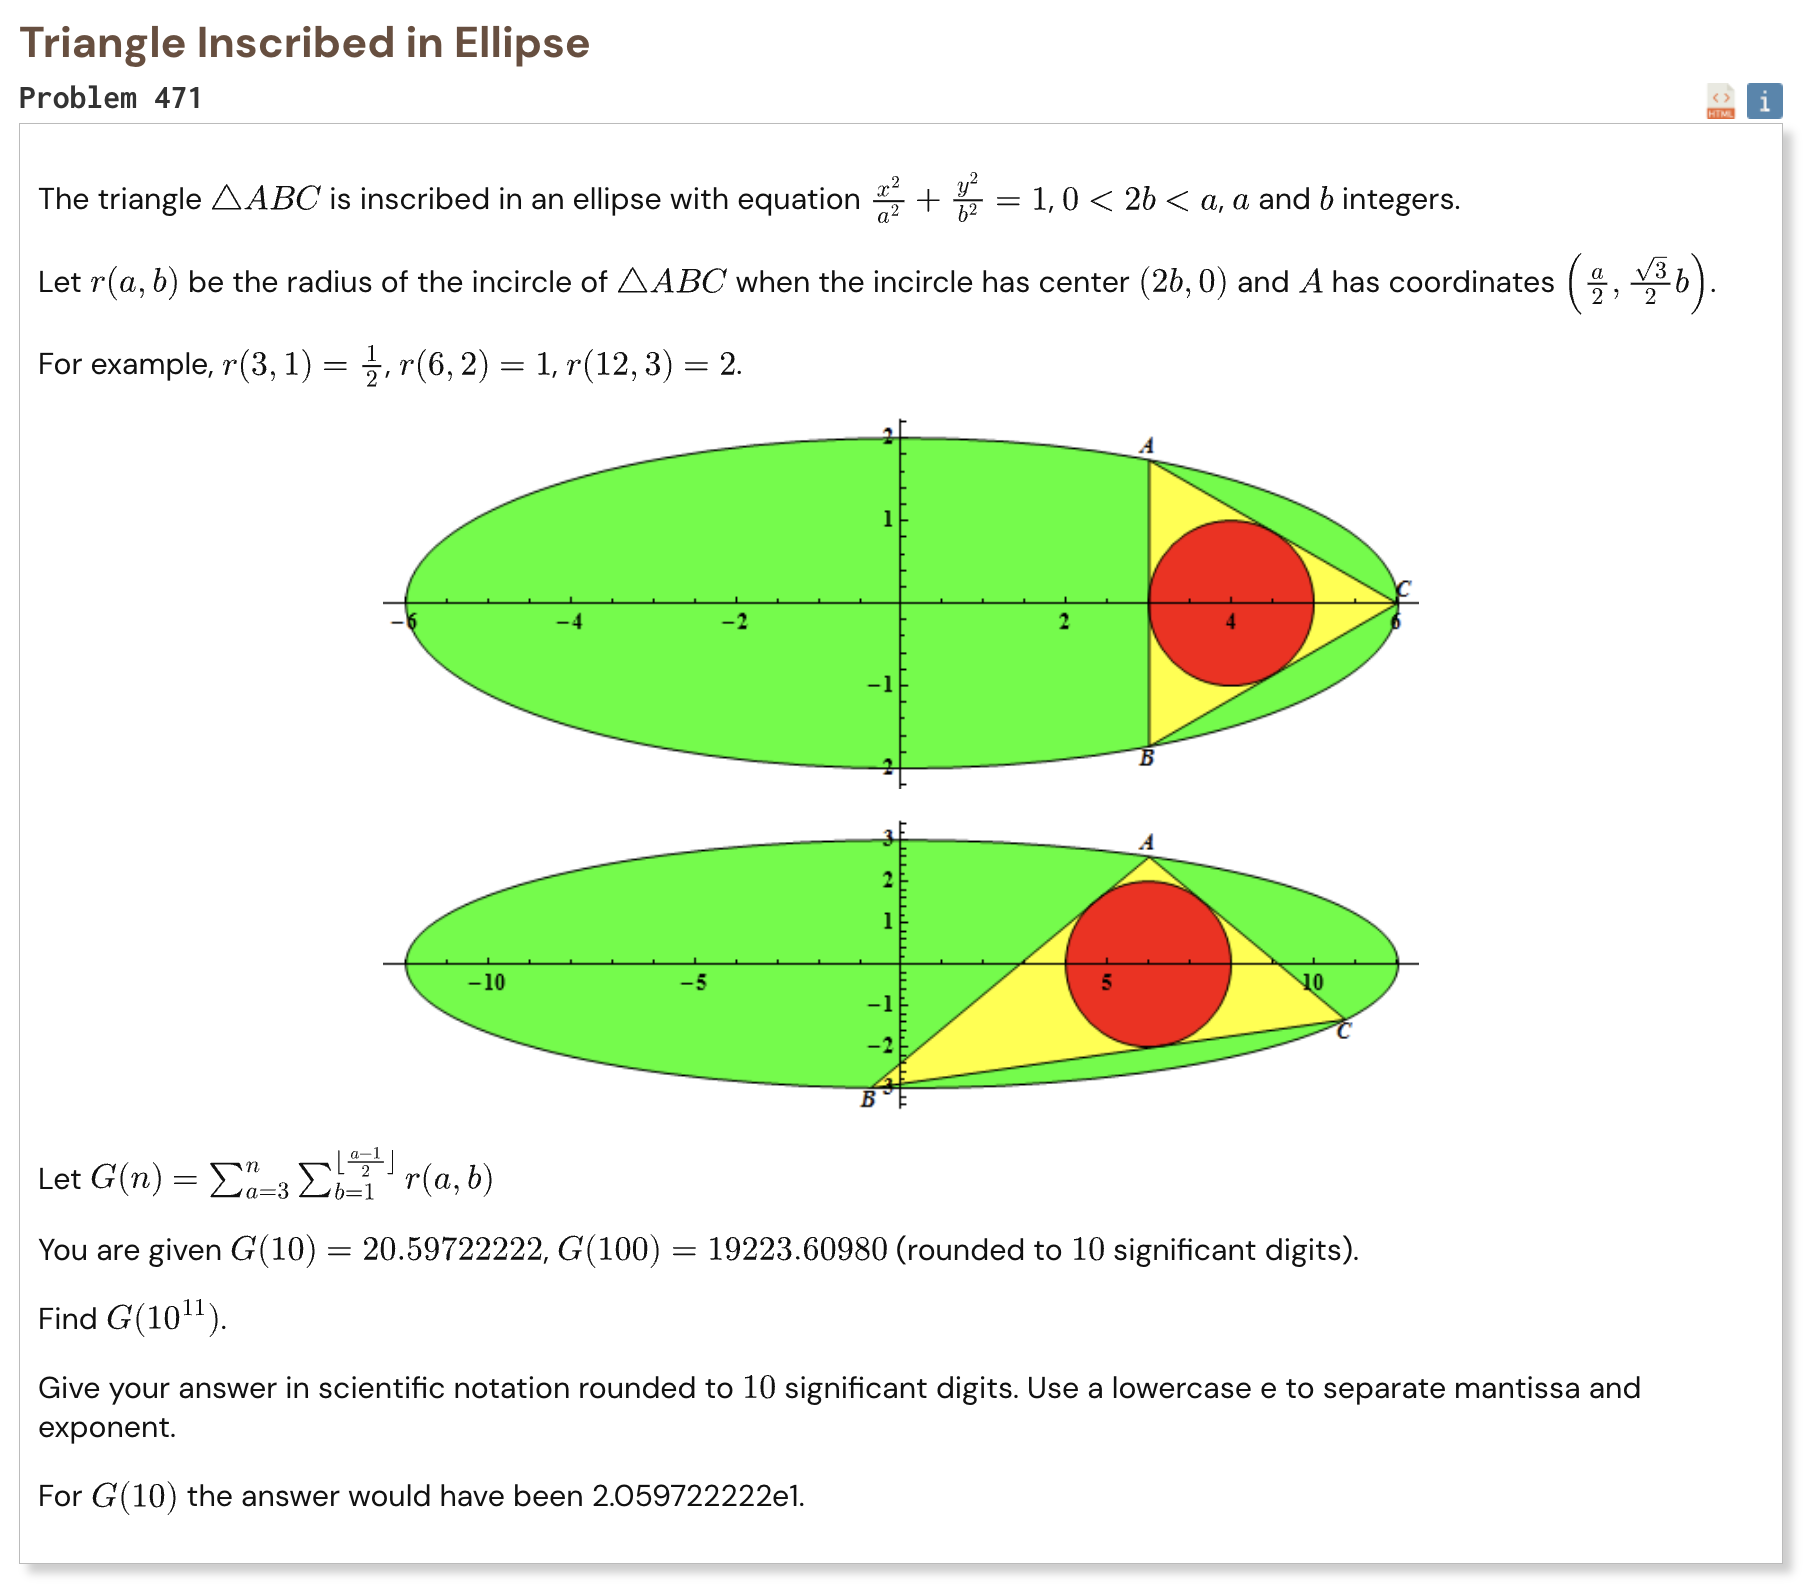

## Initial approach

- derive the inradius directly from the ellipse geometry
- reorganize the double sum using the difference between the two parameters
- most of the resulting terms reduce to ordinary polynomial sums
- the only difficult part becomes a range of harmonic numbers
- approximate the large harmonic numbers with Euler Maclaurin expansion
- use Decimal for enough precision to round the final answer correctly

In [1]:
%%time

from decimal import Decimal, getcontext

getcontext().prec = 80

N = 10**11

gamma = Decimal(
    "0.57721566490153286060651209008240243104215933593992359880576723488486772677766467"
)

def harmonic(n):
    x = Decimal(n)

    inv = Decimal(1) / x
    inv2 = inv * inv
    inv4 = inv2 * inv2
    inv6 = inv4 * inv2
    inv8 = inv4 * inv4
    inv10 = inv8 * inv2

    return (
        x.ln()
        + gamma
        + inv / 2
        - inv2 / 12
        + inv4 / 120
        - inv6 / 252
        + inv8 / 240
        - Decimal(5) * inv10 / 660
    )

n = N
q = n // 2
m = (n - 1) // 2

left = n - m
right = n - 1

harmonic_range = harmonic(right) - harmonic(left - 1)

sum_1 = Decimal((left + right) * m) / 2

sum_2 = Decimal(
    right * (right + 1) * (2 * right + 1)
    - (left - 1) * left * (2 * left - 1)
) / 6

tail = (
    Decimal(n * (n + 1) * (2 * n + 1)) * harmonic_range
    - Decimal(6 * n * n + 6 * n + 1) * m
    + Decimal(6 * n + 3) * sum_1
    - 2 * sum_2
)

low = Decimal(q * (2 * q * q + 3 * q - 5)) / 36
high = Decimal(m * (m + 1) * (m + 2)) / 6

result = low + high - tail / 6

print("Result:", f"{result:.9E}".replace("E+", "e").replace("E", "e"))

Result: 1.895093981e31
CPU times: user 461 μs, sys: 344 μs, total: 805 μs
Wall time: 1.67 ms
